# 11 · 分布式事务、Nacos、负载均衡与限流（微服务面试篇）


## 资料来源与学习路线

依据百度网盘 `我的资源/day11-微服务面试篇/PPT/微服务面试篇.pptx` 整理。**原 PPT 共 63 页，第 20、56 页隐藏，网盘预览为 61 页**；正文页码按原 PPT 顺序引用，包含两张隐藏页的知识。4 张课件原图随 Notebook 内嵌，可离线阅读。

| 课件范围 | 本篇知识 |
| --- | --- |
| 第 5—10 页 | CAP、CP/AP、BASE、事务一致性的边界 |
| 第 12—15 页 | Seata AT、脏写、全局锁、回滚数据校验 |
| 第 17—21 页 | TCC、资源预留、幂等、空回滚、业务悬挂 |
| 第 23 页 | 最大努力通知、MQ 重试、主动查询与对账 |
| 第 26—37 页 | Nacos 环境隔离、分级模型、健康检测、Eureka 对比 |
| 第 40—46 页 | Spring Cloud LoadBalancer 调用链与算法切换 |
| 第 49—62 页 | 线程隔离、固定/滑动窗口、漏桶、令牌桶 |

配套 `资料/Nacos源码分析.md`、`资料/Sentinel源码分析.md` 正文已读取，并读取 `资料/cloud-demo/pom.xml` 核对版本；讲义 `assets/` 图片及整个示例工程未下载或运行。课件目录中的“其它面试题”未另行展开，本篇按实际内容整理。

| 资料 | 可确认的版本背景 | 使用范围 |
| --- | --- | --- |
| `cloud-demo/pom.xml` | Java 8、Spring Boot 2.3.9.RELEASE、Spring Cloud Hoxton.SR10、Spring Cloud Alibaba 2.2.6.RELEASE | 配套旧示例工程，含 user-service、order-service、eureka-server |
| Nacos 源码讲义 | Nacos 1.4.2，Nacos Discovery starter 2.2.6.RELEASE | HTTP 注册、客户端心跳、UDP 推送等历史源码路径 |
| PPT 远程调用部分 | 讲 Spring Cloud 2020 之后的 LoadBalancer，示例为 hmall/item-service | 较新组件主线；不能把旧 Hoxton POM 直接当成其运行环境 |
| 本篇官方核对 | Spring Cloud Commons/Gateway 3.1.8；Seata 当前官网 v2.6 | 校正机制与补充示例，不代表 day11 工程已使用这些版本 |

“补充/校正”用于区分课件简化表述、讲义历史实现与工程条件。第 05 篇中的 Seata/Sentinel 版本标识不能直接证明 day11 工程版本。

学习顺序：**判断一致性要求 → 选事务方案 → 理解注册与发现 → 选择调用实例 → 控制进入服务的流量**。本篇未启动 Nacos、Seata、Sentinel、Gateway、MQ 或业务服务；代码和故障时间线是学习示例，验证表是复现方法。


## 1. CAP：一致、可用与网络分区分别是什么

同一份数据存放在多个节点，节点间却只能通过可能故障的网络同步。CAP 讨论的就是：**网络分区发生时，系统能否同时保证线性一致性与可用性**。（课件第 5—8、10 页）

| 指标 | 含义 | 例子 |
| --- | --- | --- |
| C：Consistency | 线性一致性；读写效果如操作一份数据，并尊重已完成操作的先后关系 | 写入 v1 已成功完成，之后的读不能再返回 v0 |
| A：Availability | 每个非故障节点收到的请求都能完成，返回符合操作语义的响应 | 不能因无法联系另一分区而无限等待或拒绝所有操作 |
| P：Partition tolerance | 节点间消息丢失、网络断开时，系统仍按选定保证处理请求 | 北京与上海失联，各自进程仍在运行 |

网络分区是节点之间的通信故障，不等于数据库分片，也不等于节点进程一定死亡。跨节点系统不能靠配置声明“永远没有分区”。

> 补充/校正：C 不是“所有副本每一瞬间物理内容都相同”；A 也不是“余额不足的扣款必须成功”。“三者任选两个”是简化说法，关键约束发生在**分区期间**。

判断业务时先问：库存扣减能否接受旧值和冲突？商品描述能否暂时显示旧版本？不同操作可以有不同的一致性要求。


## 2. CP 与 AP：分区时怎样取舍

节点 A、B 原来都保存 v0，网络断开后 A 收到“写 v1”。若允许 A 写成功，又让 B 的后续读立即返回 v0，就破坏了 C。（课件第 8、10 页）

```text
初始：A=v0，B=v0
        ↓ A、B 失联
CP 思路：仅能证明状态安全的一侧继续操作，另一侧等待或拒绝
AP 思路：两侧继续响应，允许暂时分歧，恢复后按规则同步与解决冲突
```

| 选择 | 保留的保证 | 付出的代价 | 典型适用判断 |
| --- | --- | --- | --- |
| CP | 分区时维护一致性约束 | 部分请求不能立即完成 | 不允许双卖、重复占用的关键写入 |
| AP | 分区中仍让非故障节点响应 | 可能读到旧值或产生冲突 | 可合并、可补偿的浏览与状态同步 |

采用多数派的 CP 系统，可能允许多数派继续读写，并限制少数派；并不意味着整个系统全部停机。AP 需要冲突解决规则，例如按业务版本合并；仅恢复网络并不能自动消除任意业务冲突。

> 补充/校正：课件“分区后只读就保证一致”需要前提。若一侧此前已写入 v1，落后副本只读仍可能返回 v0。必须限制读取节点或采用能保证正确结果的读协议。

实践中记录分区期间“哪些操作能继续、哪些操作拒绝、恢复后怎样收敛”，比给整个系统贴一个 CP/AP 标签更有用。


## 3. BASE 与事务一致性：补偿为何必要

跨服务操作无法总靠长时间等待保持所有资源锁定，因此允许中间状态，再通过可恢复流程完成业务。（课件第 9 页）

| BASE 思想 | 含义 | 订单例子 |
| --- | --- | --- |
| Basically Available：基本可用 | 故障时保留核心能力，允许部分功能降级 | 下单保留，推荐模块暂时关闭 |
| Soft State：软状态 | 允许一段时间处于过渡状态 | 订单“支付确认中” |
| Eventually Consistent：最终一致 | 满足恢复条件后，各方达到约定业务结果 | 重试/对账后，支付结果与订单状态一致 |

最终一致必须有实现机制：**持久化状态、重试、幂等、主动查询、对账或人工补偿**。若失败记录丢失、补偿入口不存在，等待再久也不能保证收敛。

补充/校正：分布式事务的**原子性**关心多个业务分支最终提交还是撤销；CAP 的 C 关心读写是否满足线性一致性。二者有关联，但不是同一个定义。不能把“CP”解释成所有数据库必须在物理上的同一时刻提交。

余额转移要求两方金额守恒，应设计事务或业务补偿；发送优惠券通知通常允许延迟，可采用事件驱动。选择方案时写清中间状态是否可见、失败谁负责恢复、最长能等待多久。


## 4. Seata AT：两阶段怎样减少业务侵入

订单、库存、账户分布在不同数据库，单个本地事务不能覆盖整条调用链。AT 通过代理数据源记录撤销日志，再由协调者决定全局结果。（课件第 12 页）

| 角色 | 职责 |
| --- | --- |
| TM：Transaction Manager | 发起全局事务，决定提交或回滚 |
| RM：Resource Manager | 管理分支资源、注册分支、执行本地提交与撤销 |
| TC：Transaction Coordinator | 保存全局/分支状态，协调二阶段并管理全局锁 |
| XID / BranchID | 全局事务 ID / 分支事务 ID，用于关联整个事务与具体分支 |

```text
一阶段：
业务 SQL 前读取 before-image
    → 执行业务 SQL，得到 after-image
    → 在本地事务内保存 undo_log
    → 注册分支并取得全局锁
    → 本地提交，释放数据库锁，报告分支结果

二阶段：
全局提交 → 释放全局锁，异步清理 undo_log
全局回滚 → 取得本地锁，校验当前数据，按 undo_log 恢复，完成后释放全局锁
```

`before-image` 是修改前数据，`after-image` 是修改后数据；`undo_log` 是撤销所需日志。**业务更新与 undo_log 必须处于同一个本地事务**，且本地提交前必须成功取得全局锁。

实践中检查数据源确实被代理、XID 正确传播、分支表满足该版本支持条件、undo_log 能写入。只给入口加 `@GlobalTransactional`，不能证明所有下游写入已经纳入 AT。


## 5. AT 脏写：本地提交后为什么不能盲目恢复

一阶段释放数据库行锁后，别的事务可以接着修改同一行。若二阶段只照搬旧快照，就会覆盖后来的有效业务结果。（课件第 13 页）

| 时刻 | 事务 T1 | 事务 T2 | 余额 |
| --- | --- | --- | --- |
| t0 | 修改前快照为 100 | — | 100 |
| t1 | 扣 10，本地提交 | — | 90 |
| t2 | 全局结果尚未确定 | 再扣 10 并提交 | 80 |
| t3 | 全局失败，盲目恢复为 100 | T2 的扣款被覆盖 | 错误：100 |

这个例子说明的是全局回滚覆盖另一个已提交写入的风险。若 T2 是应当保留的独立扣款，T1 撤销后的业务余额应为 90；单靠 T1 的 before-image 并不知道如何安全保留 T2。

AT 的处理分两层：**受 Seata 管理的冲突写入通过全局锁隔离；绕过 Seata 的写入通过回滚数据校验发现冲突**。仅依靠数据库本地行锁，无法把隔离延长到全局事务结束。

复现时分别测试两个 AT 分支竞争同一行，以及普通 JDBC/人工脚本修改同一行；它们经过的锁路径不同。


## 6. 数据库锁与全局锁：锁在哪里、持有多久

数据库只知道本地事务，TC 还需要知道哪一个全局事务正在占用这行资源。（课件第 14 页）

| 锁 | 管理方 | 保护范围与生命周期 |
| --- | --- | --- |
| 数据库行锁 | 数据库 | 本地事务中的并发写；本地提交/回滚后释放 |
| AT 全局锁 | TC | 纳入 AT 的全局事务对同一资源/表/主键的冲突写；持有到全局事务结束 |

全局锁不是把数据库里的锁对象搬到 TC，也不能阻止所有普通数据库写入口。

```text
T1：拿 DB 锁 → 扣款 → 拿全局锁 → 本地提交并释放 DB 锁
T2：拿 DB 锁 → 修改 → 申请同一全局锁，因 T1 持有而等待
T1：要全局回滚，需要重新拿 DB 锁，暂被 T2 阻挡
T2：全局锁有限重试失败 → 本地回滚，释放 DB 锁
T1：得到 DB 锁 → 完成撤销 → 释放全局锁
```

这解释了为何必须有**有限重试与超时退出**，避免互相等待持续不解。课件提到“默认 30 次、间隔 10ms”，属于课程版本的概述；实际参数应按所用版本和配置确认。

实践中关注热点行竞争、全局事务时长与回滚重试。库存单行被大量请求更新时，扩大重试次数会增加等待，并不能提高该行的并发写能力。


## 7. AT 的回滚校验与读取边界

全局锁只能约束参与协议的写入；人工 SQL 或未代理的数据源仍可能修改数据。AT 回滚前应比较当前数据与 after-image。（课件第 15 页）

| 数据 | 示例 |
| --- | --- |
| before-image | 余额 100 |
| T1 的 after-image | 余额 90 |
| 回滚时当前数据 | 若仍为 90，可按撤销逻辑恢复；若为 80，表明出现后续修改 |

当前数据与 after-image 不匹配时，**不能盲目用 100 覆盖 80**。应按版本的脏数据策略处理，保留事务与日志信息，告警并重试或人工核对/补偿。不能把检测到冲突等同于已经修复所有业务结果。

补充：AT 一阶段已本地提交，普通 `SELECT` 可能读到“全局尚未结束”的中间值。Seata 官方对全局读取层面描述的默认隔离为 read uncommitted；数据库本身的本地隔离级别是另一层。代理后的 `SELECT FOR UPDATE` 可结合全局锁提供特定读隔离，不能把它推广到所有普通查询。

涉及扣款决策时核对读写入口的隔离条件；查询订单可明确展示“处理中”并等待最终状态。避免声称 AT 天然提供所有请求的全局可串行化。


## 8. TCC：用资源预留表达业务

有些资源不能靠 SQL 快照恢复，或者需要业务明确控制预留与释放。TCC 把业务拆成三个阶段，由开发者实现。（课件第 17—18 页）

| 阶段 | 职责 | 从余额 100 中扣 30 的例子 |
| --- | --- | --- |
| Try | 检查条件，预留资源 | 可用余额 100→70，冻结余额 0→30 |
| Confirm | 使用已预留资源，完成业务 | 可用余额仍 70，冻结余额 30→0 |
| Cancel | 释放预留，撤销 Try 的影响 | 可用余额 70→100，冻结余额 30→0 |

```text
初始：可用 100，冻结 0
Try：可用 70，冻结 30
    ├─ Confirm：可用 70，冻结 0，已支付 30
    └─ Cancel ：可用 100，冻结 0，已支付 0
```

每个阶段可以使用独立的本地事务，原子地修改资源与阶段状态。Try 预留成功后，Confirm 应只使用预留资源，避免到 Confirm 才重新检查余额并发现不足。

> 补充/校正：“Try 成功，Confirm 一定成功”是业务设计目标。网络故障、进程退出、存储异常仍会使 Confirm 暂时失败，需要重试与幂等；不是一次调用绝不会报错。

适合可预留的余额、库存、名额；若外部动作无法撤销且不支持预留，不能简单把原操作取名 Try 就认为获得了 TCC。


## 9. TCC 协调与分支状态：恢复要有依据

进程可能在任一阶段退出，因此“上次是否冻结成功”不能只保存在内存中。（课件第 19 页；补充状态设计）

```text
TM 开启全局事务
    → 各 RM 注册分支，执行 Try，并报告结果
    → TC 根据全局决定调用 Confirm 或 Cancel
    → 未完成的二阶段持续重试，直到获得确定结果
```

分支状态记录至少关联全局事务、具体分支/业务操作、资源 ID、金额/数量及状态。幂等键可以采用 `(XID, BranchID)` 或业务设计的唯一操作 ID；**同一个用户可能有多笔扣款，不能只用 userId 去重**。

| 当前状态 | 允许的操作 | 资源变化 |
| --- | --- | --- |
| 无记录 | Try→TRIED | 检查并冻结一次 |
| TRIED | Confirm→CONFIRMED | 消耗冻结资源一次 |
| TRIED | Cancel→CANCELLED | 释放冻结资源一次 |
| 无记录 | 空 Cancel→CANCELLED | 留取消标记，资源不变 |
| CONFIRMED / CANCELLED | 相同操作的重试 | 返回已有结果，资源不再变 |

状态记录与资源变更必须在本地事务中一起完成，并使用唯一约束、锁或条件更新处理并发。终态不能随意互换；已确认后的退款属于新的业务补偿流程。

复现时在“资源修改完成但返回前”制造失败，再重试同一分支，检查记录与金额是否仍一致。


## 10. TCC 幂等：重复回调为何不能重复扣钱

调用方超时，不代表服务端未成功。TC 重试 Confirm/Cancel 是正常恢复机制，因此业务必须允许同一操作被重复调用。（课件第 21 页）

| 操作 | 首次有效执行 | 重复执行 |
| --- | --- | --- |
| Try | 预留资源，写 TRIED | 检查同一幂等键与参数，返回已执行结果 |
| Confirm | TRIED→CONFIRMED，消耗预留 | 已 CONFIRMED 则成功返回，不再消耗 |
| Cancel | TRIED→CANCELLED，释放预留 | 已 CANCELLED 则成功返回，不再释放 |

```text
本地事务开始
    → 读取/创建该分支状态，互斥或条件更新
    → 校验本次参数与首次请求一致
    → 检查合法状态迁移
    → 资源变更 + 状态变更
本地事务提交
```

不能把“先查不存在，再插入”当成完整并发去重：两个请求都可能查到不存在，需要数据库唯一约束兜底。同一幂等键传来不同金额，应拒绝或告警，不能静默当成相同操作。

Confirm 遇到无预留或已取消状态，需要按协议明确失败/异常处理；不要凭空扣款。Cancel 遇到已确认状态，也不能直接再加回余额。


## 11. 空回滚与业务悬挂：Cancel 可能先到

Try 因网络或线程阻塞迟迟未进入业务，全局事务却已经超时回滚，Cancel 可能先于 Try 到达。（**课件隐藏第 20 页**）

```text
Try 请求延迟
    → 全局超时，Cancel 先到
    → 尚未预留：不释放资源，但持久化 CANCELLED 标记
    → 延迟的 Try 随后到达
    → 发现已取消，拒绝预留，资源不变
```

**空回滚**：Try 尚未执行，Cancel 不应释放不存在的预留。**业务悬挂**：如果 Cancel 后仍允许延迟的 Try 冻结资源，协调流程已结束，资源可能无法再释放。

| 处理方式 | 结果 |
| --- | --- |
| 空 Cancel 直接返回，未留记录 | 后来的 Try 不知道已取消，可能悬挂 |
| 空 Cancel 写取消标记；Try 检查标记 | 阻止回滚之后再预留 |
| Try/Cancel 各自先查再改，缺少并发约束 | 仍可能同时穿过检查并留下冻结资源 |

取消标记与 Try 的预留操作必须通过同一幂等键、唯一约束与本地事务互斥。标记保留时间应覆盖延迟、重试及恢复周期，过早清理会重新暴露悬挂问题。

测试顺序至少覆盖 Cancel→Try、Try→Cancel、Try 与 Cancel 并发，以及重复 Cancel。


## 12. AT 与 TCC：怎样按资源特点选

两者都分两阶段，但“如何恢复资源”和“业务需要写多少代码”不同。（课件第 12、17、21 页）

| 维度 | AT | TCC |
| --- | --- | --- |
| 一阶段 | 业务 SQL + 撤销日志，本地提交 | 业务检查 + 资源预留 |
| 二阶段提交 | 清理撤销日志 | Confirm 消耗预留 |
| 二阶段回滚 | 校验并用撤销日志恢复 | Cancel 释放预留 |
| 冲突控制 | 数据库锁、全局锁 | 业务预留、状态约束及本地并发控制 |
| 业务侵入 | 通常较低，受数据源/SQL 支持限制 | 较高，需要设计三个阶段与恢复 |
| 适合资源 | 可被代理和撤销的关系型数据库写入 | 有预留能力、可定义确认/取消语义的资源 |

补充/校正：TCC 可以不依赖 AT 的 SQL 快照与全局锁，但仍要保证本地阶段的原子性、并发安全与幂等。不能由此说它“完全不依赖事务”或在任何业务里“性能最强”。

关系型数据库 CRUD、改造成本敏感时，可评估 AT；库存名额有清晰冻结模型，或涉及多类资源时，可评估 TCC。最终还要比较热点竞争、失败恢复成本、中间状态可见性与团队维护能力。


## 13. 最大努力通知：消息之外为什么要有查询入口

支付成功后通知订单服务，双方可能跨系统，通知方无法无限等待。最大努力通知通过多次通知提高到达概率，再给接收方主动查询的机会。（课件第 23 页）

```text
支付结果持久化
    → 发送结果通知
    → 失败按策略重试，成功记录接收结果
    → 达到重试边界仍不确定：保留失败记录并告警
订单侧仍不确定
    → 按支付单号主动查询
    → 对账并幂等更新订单状态
```

通知次数、间隔和最终处理应明确；重试可指数退避并增加抖动，减少故障恢复时同时重发。接收方需提供幂等处理，发送方需提供可信、可查询的结果记录。

最大努力强调“尽力送达”，不等于有限重试后自动保证最终一致。如果通知永远不到达，也没有查询/对账，订单就可能永久处于错误状态。

适合支付结果、跨系统状态同步；金额与订单终态仍应通过查询和对账核实。短信发送成功则不等于用户已阅读，也不能拿消息到达作为业务完成的证据。


## 14. MQ confirm、ACK 与业务提交：三个成功不能混用

“发了 MQ”不能解决数据库与消息发送的原子性，也不能证明消费者已提交业务。（课件第 23 页；结合第 06、07 篇补充）

| 信号/动作 | 能说明什么 | 不能说明什么 |
| --- | --- | --- |
| 生产者 confirm | Broker 按配置接受了消息 | 消费者已处理并提交 |
| 消费者业务事务提交 | 本次数据更新已持久化 | Broker 已收到 ACK |
| 消费者 ACK | Broker 可结束本次消息投递 | 业务天然具备幂等或发送端天然原子 |

补充可靠发送：使用 **Outbox**，把业务结果与待发送事件写进同一个本地事务，再由后台任务发送；发送确认后标记事件完成。任务崩溃可能重发，所以事件 ID 必须用于消费去重。

```text
生产端：业务结果 + Outbox 同事务提交 → 后台可靠发送与重试
消费端：收到事件 → 去重检查 + 业务更新同事务提交 → ACK
异常路径：有限重试 → 失败记录/死信与告警 → 查询/对账补偿
```

消费提交后 ACK 前崩溃会导致重复投递；先 ACK 再提交则可能丢失业务更新。采用提交后 ACK 与幂等，追求可恢复的业务结果，不能简单承诺跨系统“只投递一次”。


## 15. Namespace、Group、DataId：环境怎样隔离

开发、测试、生产可能使用相同服务名和配置名，需要按逻辑空间区分，避免测试实例被生产调用。（课件第 26—30 页）

| 概念 | 服务发现中的用途 | 配置管理中的用途 |
| --- | --- | --- |
| Namespace | 隔离环境中的服务与实例 | 隔离环境中的配置 |
| Group | 同一 Namespace 内的服务分组 | 同一 Namespace 内的配置分组 |
| ServiceName | 逻辑服务名称，如 item-service | 不代替 DataId |
| DataId | 不用于标识具体实例 | 标识配置，如 item-service-dev.yaml |

配置通常由 `Namespace + Group + DataId` 定位；发现服务要匹配 Namespace、Group 与服务名。服务注册成功但调用方看不到，先检查这组身份，而不只检查服务器 IP。

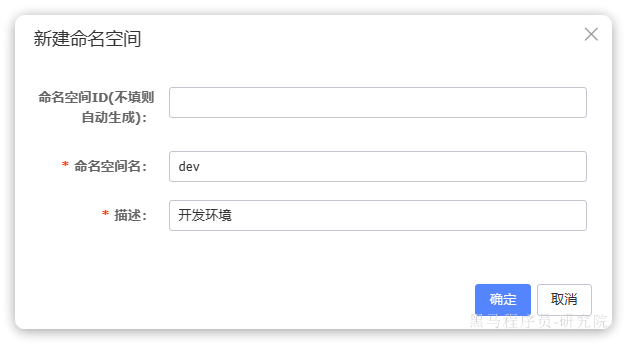

原图中的 `dev` 是**命名空间名称**。客户端 `namespace` 要填写控制台的命名空间 **ID**；留空自动生成 ID 时，ID 不会自动等于 dev。

补充：逻辑隔离不代替鉴权或网络隔离。还应控制谁能改生产配置、注册生产实例；`spring.profiles.active=dev` 也不会自动把 Nacos Namespace 切换为 dev。


## 16. 发现与配置的 Namespace 要分别设置

一个服务可能“从测试环境读配置，却把实例注册到默认空间”，所以 discovery 与 config 两部分需要同时核对。（课件第 30 页）

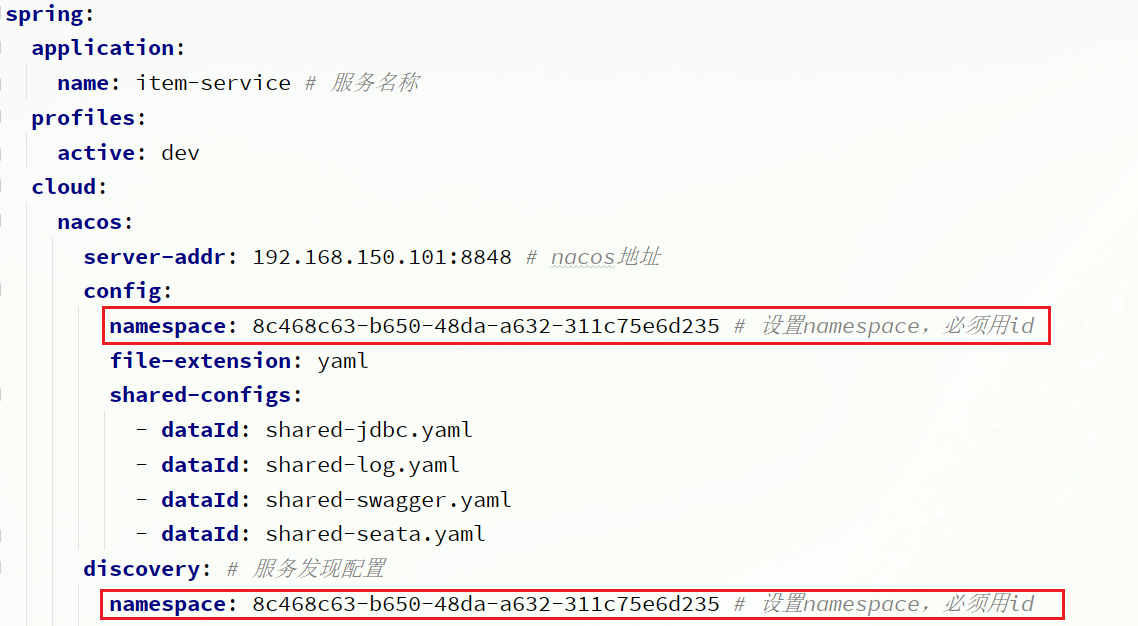

以下是对原图的整理示例，用环境变量替代课件地址和 UUID，保留四个 shared-configs 的名字：

```yaml
spring:
  application:
    name: item-service
  profiles:
    active: dev
  cloud:
    nacos:
      server-addr: ${NACOS_SERVER_ADDR:127.0.0.1:8848}
      discovery:
        namespace: ${NACOS_NAMESPACE_ID}
        group: DEFAULT_GROUP
        cluster-name: HZ
      config:
        namespace: ${NACOS_NAMESPACE_ID}
        group: DEFAULT_GROUP
        file-extension: yaml
        shared-configs:
          - data-id: shared-jdbc.yaml
            group: DEFAULT_GROUP
          - data-id: shared-log.yaml
            group: DEFAULT_GROUP
          - data-id: shared-swagger.yaml
            group: DEFAULT_GROUP
          - data-id: shared-seata.yaml
            group: DEFAULT_GROUP
```

`NACOS_NAMESPACE_ID` 必须指向实际 ID；`HZ` 是示例机房集群名。扩展名、DataId、Group 要与控制台文件匹配。使用旧 starter 时还要按该版本确认配置加载阶段，例如 bootstrap 配置要求；新版配置导入方式应查匹配版本，不能直接混用。

实践中分别检查：配置来自哪个空间、服务注册到哪个空间、调用方查询哪个空间。不要仅靠配置文件显示 `dev` 判断环境隔离已完成。


## 17. Nacos 分级模型：服务、集群、实例怎么关联

一个逻辑服务可以部署在不同机房，每个机房又有多个进程。Nacos 用集群描述机房/区域，用实例描述具体地址。（课件第 32—33 页）

```text
Namespace：某个环境
└─ Group::ServiceName：DEFAULT_GROUP::item-service
   └─ Service
      ├─ Cluster：HZ
      │  ├─ Instance：10.0.1.11:8081
      │  └─ Instance：10.0.1.12:8081
      └─ Cluster：SH
         └─ Instance：10.0.2.11:8081
```

课件与 1.4.2 讲义中的服务端组织可以概括为：

| 层级 | 典型结构 |
| --- | --- |
| Namespace → 服务键 → Service | `Map<String, Map<String, Service>>` |
| Service → 集群 | `Map<String, Cluster>` |
| Cluster → 实例集合 | `Set<Instance>`，区分临时/非临时实例集合 |

`group::serviceName` 是服务键的组合方式，避免不同 Group 的同名服务混淆。端口不同、机器不同都可能对应不同实例。

**业务实例的 HZ/SH 集群**，与**部署多台 Nacos Server 组成的注册中心集群**不是一个概念。同集群优先调用是一种客户端选择策略，分级存储本身不会自动保证所有请求都就近路由。


## 18. Nacos 1.4.2 注册链：自动注册从哪里开始

应用的 HTTP 端口启动完成后，框架才知道可注册的实例地址。配套讲义把 Spring Cloud 自动注册与 Nacos 客户端串起来。（配套 Nacos 讲义第 2 章）

```text
WebServerInitializedEvent
    → NacosAutoServiceRegistration
    → NacosServiceRegistry
    → NacosNamingService.registerInstance()
    → NamingProxy
    → HTTP POST /nacos/v1/ns/instance
    → 服务端 InstanceController
    → ServiceManager 创建/取得 Service，并注册 Instance
```

自动注册把应用名、Namespace、Group、集群、IP、端口、是否临时等配置转换为实例数据。临时实例还会创建 `BeatInfo`，交给 `BeatReactor` 调度心跳。

接口调用成功不等于所有调用方已立即收到更新：服务端事件、节点同步与客户端缓存刷新都有时间差。

该链是 **Nacos 1.4.2 + 旧 starter 的历史实现**。升级后应按实际客户端/服务端版本查看实现与通信协议；不能仅凭课程类名就认定新版仍使用同一条 HTTP/UDP 路径。

排查注册失败时沿链检查自动注册开关、服务身份、可达地址、Server 日志和实例健康状态。容器注册不可达的宿主地址，即使控制台有记录也不能正常调用。


## 19. 服务端并发与 Distro：为什么不把所有更新都同步串行

注册中心读多写少，但实例变更需要安全更新本地集合，并传播到其他节点。配套 1.4.2 讲义展示服务级锁、事件队列与异步同步。（配套 Nacos 讲义第 2.3 章）

| 机制 | 解决的问题 | 边界 |
| --- | --- | --- |
| Service 粒度的同步控制 | 避免同一服务更新互相覆盖 | 热点服务的写更新仍会竞争 |
| CopyOnWrite 实例集合 | 更新时复制并替换集合，减少遍历读与修改冲突 | 写入有复制成本，不代表所有状态都强一致 |
| Notifier 事件队列 | 把数据变更通知交给监听者异步处理 | 队列可能积压，事件完成有延迟 |
| Distro 异步同步与重试 | 把临时实例变化传播到其他 Nacos 节点 | 节点间允许短暂不同步 |

```text
临时实例注册/变更
    → 更新本地数据记录
    → 排入 Notifier 变更事件，通知监听者更新实例集合
    → Distro 向其他节点异步同步，失败重试
    → 触发订阅客户端的列表更新
```

讲义中 Notifier 用单线程处理其队列，不能据此说 Nacos 所有请求都只有一个线程。CopyOnWrite 也不能证明无限并发或零锁竞争。

排障时看“注册写入、监听更新、节点同步、客户端通知”哪个环节滞后；只看一次控制台截图，无法解释调用方为何仍使用旧列表。


## 20. 临时与非临时实例：心跳、探测和摘除

进程退出后，注册信息不会自己消失；注册中心需要依据健康信号决定是否继续提供该地址。（课件第 35—37 页；配套 Nacos 讲义第 3 章）

| 类型 | 1.4.2 讲义中的检测方式 | 故障后行为 |
| --- | --- | --- |
| 临时实例 | 客户端 `BeatReactor/BeatTask` 主动发心跳 | 超时标记不健康，进一步超时删除 |
| 非临时实例 | 服务端主动健康检测，如 TCP 探测 | 标记不健康，保留注册记录 |

讲义中的常见默认量级：临时实例约 **5 秒**发心跳；距最后心跳超过 **15 秒**可标记不健康，超过 **30 秒**可删除。任务调度、网络延迟、配置变化会影响实际时间，不能说“宕机后精确第 15 秒必然摘除”。

```text
客户端：定时发心跳
服务端：更新 lastBeat，恢复/维持健康状态
检测任务：比较当前时间与 lastBeat
    → 超健康阈值：healthy=false，并通知变更
    → 超删除阈值：删除临时实例，并通知变更
```

“非临时/永久”指注册记录的保留语义，不表示永远健康。服务调用通常只选健康可用实例；保留故障记录与继续把故障地址发给正常请求不是一回事。

测试时区分正常注销、强制结束进程、心跳网络中断。注册中心探测结果也不能替代业务接口的错误率和调用超时。


## 21. 服务发现：本地缓存、定时拉取与变更推送

若每个请求都远程访问注册中心拿列表，注册中心会变成业务瓶颈。客户端使用本地服务信息，再用拉取和推送更新。（课件第 36—37 页；配套 Nacos 讲义第 4 章）

```text
首次/需要刷新服务信息
    → NacosNamingService 查询
    → HostReactor 读取/更新本地服务缓存
    → 定时任务继续拉取列表

服务端发现实例变化
    → 向订阅客户端发送 UDP 通知（1.4.2 路径）
    → PushReceiver 接收
    → HostReactor.processServiceJson() 更新缓存
    → 发布变更事件，通知订阅者
```

推送提高更新及时性，定时更新则参与补齐信息；两者不能证明没有延迟、乱序或短时丢失。客户端拿到列表后，仍要通过负载均衡选择一个实例，并处理连接失败。

补充/校正：讲义口头称 UDP“广播”，这里理解为**向订阅客户端推送服务变化**，不能直接推断成 IP 层广播到整个网络。

实践中检查客户端缓存里的健康实例、服务端的实际列表、最近更新时间和通知连通性。控制台已删除一个实例而短时仍有请求发向它，可能与发现缓存或已有连接有关。


## 22. Eureka 与 Nacos：共同流程与一致性差异

两者都让提供者登记地址，让调用者发现实例；区别集中在健康检测、变化传播和数据一致性路径。（课件第 35—37 页）

| 维度 | Eureka 课程模型 | Nacos 课程/1.4.2 模型 |
| --- | --- | --- |
| 注册与发现 | 注册、续约、客户端拉取与缓存 | 注册、客户端拉取与缓存 |
| 临时实例健康信号 | 提供者心跳续约，常见约 30s | 临时实例心跳，讲义常见约 5s |
| 服务端主动检测 | 课程主线不是该方式 | 非临时实例可主动探测 |
| 变化传播到客户端 | 以拉取为主 | 拉取 + 服务变更推送 |
| 集群一致性主线 | 常用 AP 模型理解 | 临时实例走 Distro/AP；持久实例有不同一致性路径 |
| 配置中心 | 注册中心本身不等同配置中心 | Nacos 还提供配置管理，需单独理解其一致性机制 |

补充/校正：“Nacos 默认 AP，可以切 CP”应按数据类型与协议路径理解。1.4.2 一致性委托会区分临时与持久实例；**不是打开一个开关，所有注册数据、客户端缓存、配置数据就一起获得相同保证**。

Eureka 的自我保护会在异常续约比例下影响实例剔除，不能只用“心跳更慢”解释全部故障行为；这是补充边界，具体阈值按版本确认。

面试回答可先说明共同的注册→健康→发现→调用流程，再比较机制和版本。不要把“控制台现在显示健康”当成端到端业务可用性的证明。


## 23. 客户端负载均衡：服务名怎样变成地址

调用方只知道 `item-service`，该服务却可能有多个实例。客户端负载均衡负责从候选列表选地址，注册中心负责提供候选信息。（课件第 40 页）

```text
逻辑请求：http://item-service/items?ids=110
    → 根据 serviceId=item-service 获得候选实例
    → 按策略挑选一个，如 10.0.1.11:8081
    → 重构 URI：http://10.0.1.11:8081/items?ids=110
    → HTTP 客户端直接向目标实例发送业务请求
```

| 组件 | 职责 |
| --- | --- |
| DiscoveryClient | 统一服务发现接口，返回某个服务的实例信息 |
| ServiceInstanceListSupplier | 为 LoadBalancer 提供实例列表，可叠加缓存/过滤等能力 |
| LoadBalancer | 选择目标实例 |
| HTTP 客户端 | 建立连接、发送请求、接收响应 |

注册中心通常不代理这次业务 HTTP 请求。列表可能来自客户端缓存，也可能经过 LoadBalancer 的缓存，不能把“查询列表”理解成每个请求都远程访问 Nacos。

实践中先确认有效候选列表，再检查策略和连接；列表为空与目标地址连接超时属于不同问题。客户端已有缓存时，还应评估叠加缓存带来的更新延迟。


## 24. OpenFeign + LoadBalancer：源码调用链

PPT 讲的是 Spring Cloud 2020 之后以 Spring Cloud LoadBalancer 替代 Ribbon 的主线。Feign 把接口方法转为请求，LoadBalancer 再把服务名路由到实例。（课件第 40—42 页）

```text
Feign 生成 http://item-service/items?ids=110
    → FeignBlockingLoadBalancerClient 取 URI 中的 serviceId
    → BlockingLoadBalancerClient.choose(serviceId)
    → 按服务取得 ReactiveLoadBalancer
    → choose()，通过 ServiceInstanceListSupplier 得到列表
    → 默认 RoundRobinLoadBalancer 选择实例
    → 重构 URI，交给底层 HTTP 客户端执行
```

`BlockingLoadBalancerClient` 连接阻塞调用路径与响应式策略接口；`ReactiveLoadBalancer` 使用 Reactor 的返回类型表达选择结果。**类名中有 Reactive，不代表整条 Feign 阻塞调用自动变成异步**。

Gateway 的 `lb://item-service` 可通过 `ReactiveLoadBalancerClientFilter` 解析实例，然后交给网关 HTTP 客户端转发；它与 Feign 的入口适配类不同，但都可使用 LoadBalancer。

实践中检查匹配版本的 `spring-cloud-starter-loadbalancer` 及发现组件。配套 Hoxton 工程属于较旧栈，不应原封不动套上本节类名和配置；先统一 Spring Boot、Cloud、Alibaba 的兼容版本。


## 25. 轮询、随机与 Nacos 策略：各自保证什么

实例数量相同，不代表每台机器性能相同、每次请求耗时相同，也不代表都在同一机房。（课件第 44 页）

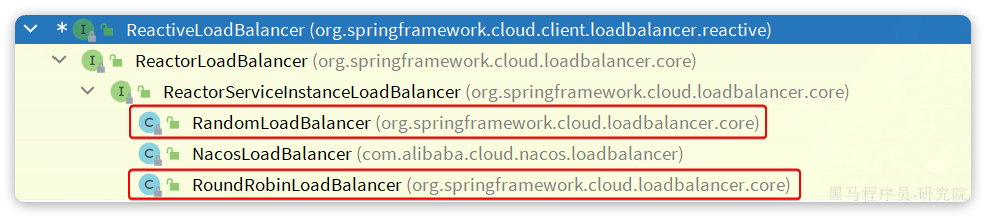

| 策略 | 主要行为 | 判断边界 |
| --- | --- | --- |
| RoundRobinLoadBalancer | 轮流选择候选列表中的实例，Spring Cloud 的默认实现 | 候选变化、初始位置、请求耗时会影响短时负载 |
| RandomLoadBalancer | 在候选实例中随机选择 | 短时间不一定均匀，长期统计才接近概率分布 |
| NacosLoadBalancer | 按匹配版本的 Nacos 实现，通常考虑同集群优先、实例权重 | 来自 Alibaba 组件，不能假定所有版本实现完全一致 |

同集群优先减少跨机房流量；无可用同集群实例时是否跨集群、如何加权，应检查实际实现与配置。权重影响选择概率，不等于为实例预留固定并发配额。

补充：默认轮询不会因为 Nacos 控制台设置了权重就必然按权重分配。必须确认当前调用实际启用了读取这些属性的策略。

验证时记录真实目标 IP/端口和请求计数，固定候选列表后采样；只看连续两次响应来自不同实例，无法证明加权策略正确。


## 26. 切换策略：配置类、服务范围与版本要一起核对

策略由对应服务的 LoadBalancer 上下文创建，覆盖其 Bean 可以替换默认选择逻辑。（课件第 45—46 页；官方 Commons 3.1.8 核对）

以下是官方 Random 示例的完整整理。配置类**不加 `@Configuration`**，也不作为普通组件扫描，避免误变成所有服务共享的主上下文配置：

```java
package com.example.lb;

import org.springframework.cloud.client.ServiceInstance;
import org.springframework.cloud.loadbalancer.core.RandomLoadBalancer;
import org.springframework.cloud.loadbalancer.core.ReactorLoadBalancer;
import org.springframework.cloud.loadbalancer.core.ServiceInstanceListSupplier;
import org.springframework.cloud.loadbalancer.support.LoadBalancerClientFactory;
import org.springframework.context.annotation.Bean;
import org.springframework.core.env.Environment;

public class RandomLoadBalancerConfiguration {
    @Bean
    public ReactorLoadBalancer<ServiceInstance> randomLoadBalancer(
            Environment environment,
            LoadBalancerClientFactory factory) {
        String serviceId =
                environment.getProperty(LoadBalancerClientFactory.PROPERTY_NAME);
        return new RandomLoadBalancer(
                factory.getLazyProvider(serviceId, ServiceInstanceListSupplier.class),
                serviceId);
    }
}
```

启动类按**单服务**指定配置，类名与包名为补充示例：

```java
package com.example.app;

import com.example.lb.RandomLoadBalancerConfiguration;
import org.springframework.boot.SpringApplication;
import org.springframework.boot.autoconfigure.SpringBootApplication;
import org.springframework.cloud.loadbalancer.annotation.LoadBalancerClient;

@SpringBootApplication
@LoadBalancerClient(
        name = "item-service",
        configuration = RandomLoadBalancerConfiguration.class)
public class Application {
    public static void main(String[] args) {
        SpringApplication.run(Application.class, args);
    }
}
```

若想为所有服务指定默认配置，课件使用 `@LoadBalancerClients(defaultConfiguration = XxxConfiguration.class)`；不要同时照搬单服务与全局设置而不判断生效范围。

PPT 的 Nacos Bean 工厂核心是下面三个参数（整理片段，置于对应配置类的 Bean 方法内）：

```java
String serviceId =
        environment.getProperty(LoadBalancerClientFactory.PROPERTY_NAME);
return new NacosLoadBalancer(
        factory.getLazyProvider(serviceId, ServiceInstanceListSupplier.class),
        serviceId,
        properties);
```

其中 `properties` 为 `NacosDiscoveryProperties`，NacosLoadBalancer 来自 `com.alibaba.cloud.nacos.loadbalancer`。构造器与自动配置随 Alibaba 版本变化，本片段只适用于匹配该签名的版本；不能在旧 Hoxton 工程中仅复制片段就宣称已切换成功。


## 27. 远程调用排障：从身份查到请求预算

调用失败不一定是负载均衡算法的问题。按分层证据判断，才能避免不断更换策略却仍访问不到服务。（课件第 40—46 页；补充排障）

| 现象 | 优先核对 |
| --- | --- |
| 没有候选实例 | Namespace、Group、服务名、注册与健康状态 |
| 选到了实例但连接失败 | 注册 IP/端口、容器网络、监听地址、连接超时 |
| 仍访问已下线实例 | 发现缓存、LoadBalancer 缓存、通知与刷新延迟 |
| 权重/同集群似乎没生效 | 实际策略 Bean、服务配置范围、元数据和组件版本 |
| 调用固定地址，服务名策略不生效 | 是否配置 `@FeignClient(url=...)`，绕过了按服务名发现 |
| 重试后出现重复扣款 | 操作幂等性、请求 ID、服务端是否已提交 |

连接超时控制建连等待，读取超时控制等响应等待；多次重试会扩大总时长。入口请求有总预算时，应让各层超时与重试共同受预算限制，避免下游已超时、上游仍持续占用资源。

超时是“未在期限内收到确定结果”，不证明下游没有执行。查询类可评估重试；扣款、创建订单等写操作先设计幂等与结果查询，再决定是否重试。


## 28. Sentinel：资源、调用上下文与统计节点

限流规则必须知道“保护哪项操作”，而不仅是看到整个进程的请求数。配套讲义从资源入口与责任链解释 Sentinel 的执行。（配套 Sentinel 讲义第 1—2 章）

| 名称 | 含义 |
| --- | --- |
| Resource | 被保护的资源名，如接口、方法或远程调用 |
| Entry | 一次进入资源的访问记录，退出时完成统计 |
| Context | 调用入口与上下文，组织资源调用关系 |
| DefaultNode | 当前调用链中资源的统计节点 |
| ClusterNode | 同一进程内按资源聚合的统计节点 |
| ProcessorSlotChain | 插槽组成的责任链，完成统计与规则检查 |

```text
进入资源
    → 建立调用链/资源统计节点
    → 统计 + 授权/系统/热点/流控/熔断等规则检查
    → 放行执行，或抛出 BlockException
退出资源
    → 更新并发、响应时间、成功/异常等统计
```

讲义涉及 NodeSelectorSlot、ClusterBuilderSlot、StatisticSlot、AuthoritySlot、SystemSlot、ParamFlowSlot、FlowSlot、DegradeSlot 等；实际装配由版本与 SPI 扩展决定，不能把某次顺序说成永远固定。

补充/校正：`ClusterNode` 的名字不表示“所有服务器实例的全局统计”。普通本地模式阈值通常按进程执行；分布式总额度需要单独的集群流控或集中限额机制。

业务异常要按接入方式正确记录给熔断统计；`BlockException` 是保护规则拒绝，不能与业务抛错混为一谈。DegradeSlot 通过 Closed→Open→HalfOpen 和请求完成结果判断恢复，熔断不是杀掉当前正在执行的调用。


## 29. 线程池隔离与信号量隔离：慢调用会占用谁

一个下游变慢，会长期占用调用方线程。若所有依赖共用相同资源，局部故障可能拖住整个入口。（课件第 49—50 页）

| 维度 | Hystrix 默认线程池隔离 | Sentinel 信号量式隔离 |
| --- | --- | --- |
| 执行线程 | 提交到配置的隔离线程池 | 通常在当前请求线程执行 |
| 准入条件 | 有可用线程/队列位置 | 当前并发计数未达到阈值 |
| 超额处理 | 拒绝或降级 | 拒绝或降级 |
| 代价 | 线程、队列与调度开销 | 计数与规则检查，开销相对低 |
| 隔离范围 | 限定该池的执行资源 | 限定并发准入，不提供独立线程池 |

这里“信号量”可理解为计数准入机制，不必推断为每个资源都创建 `java.util.concurrent.Semaphore`。Hystrix 的线程池粒度也可以配置和共享，并非每个方法必有一个全新线程池。

补充/校正：Sentinel 达到并发上限会阻止后续进入，但**不会终止已在当前线程里阻塞的调用**。线程池隔离也不能自动隔离所有数据库连接或共享内存，更不能保证远程操作被取消。

实践中给下游设置合理超时、限制并发，并避免无界队列。依赖经常慢且需要独立执行资源时，可评估线程池隔离；只需低开销准入时，并发阈值更直接。


## 30. QPS、并发与响应时间：阈值为什么不能互换

每秒允许 100 次，不代表只占用 100 个线程；调用越慢，同一时刻积压的请求越多。（课件第 49—50 页；补充）

| 指标 | 计量内容 | 适合判断 |
| --- | --- | --- |
| QPS | 单位时间请求/通过次数 | 限制到达或放行速率 |
| 并发数 | 已进入但尚未退出的请求数 | 控制正在占用的资源 |
| RT：响应时间 | 一次调用从开始到完成的耗时 | 估算资源占用、识别慢调用 |

稳定状态下可近似使用 **并发 ≈ 吞吐率 × 平均响应秒数**。100 QPS、平均 0.2 秒，对应平均约 20 个在途请求；若变成 2 秒，则约 200 个。突发流量、超时、排队与长尾延迟会使瞬时值偏离这个均值。

QPS 阈值需要与服务处理能力匹配；并发阈值需要与线程、连接池和内存预算匹配。对数据库慢查询，仅调低 QPS 而不限制并发，仍可能累积大量等待。

确认规则计量的是尝试次数、通过次数还是完成次数，并把失败/阻断指标一起观察。不能把“限流到每秒 100”直接解释成“最多 100 个线程”。


## 31. 固定窗口：边界为何出现突发

固定窗口用很少的状态限制每段时间的次数，但相邻窗口独立，边界附近可能瞬间通过两倍额度。（课件第 52—54 页）

以窗口 1000ms、每窗最多 3 次为例，按请求时间 t 分配到 `floor(t / 1000)` 对应窗口，在同一窗口原子计数并判断额度。

| 请求时间 | 所属窗口 | 放行数量 |
| --- | --- | --- |
| 999ms | [0, 1000) | 3 次 |
| 1001ms | [1000, 2000) | 3 次 |

两个窗口都合规，**2ms 内却放行了 6 次**。它限制的是对齐窗口内次数，不能保证任意最近 1 秒最多 3 次。

```text
确定当前窗口 → 原子检查/增加计数 → 未超阈值放行，否则拒绝
跨越窗口边界 → 使用新窗口计数
```

适合允许边界突发、希望实现简单的粗粒度限额。补充：Redis 实现要把计数与 TTL 设置的关键步骤做成原子操作，避免计数存在却没有过期时间；先读再写的非原子判断会被并发绕过。


## 32. 分桶滑动窗口：更平滑，但仍有精度边界

把 1 秒划分成多个小桶，随着时间移动只统计当前有效桶，可以减轻固定大窗口的边界突发。（课件第 55 页、**隐藏第 56 页**）

课程例子：`Interval=1000ms`、`n=2`，每桶 500ms，阈值为 3。

| 当前时间 | 参与统计的桶 | 被排除的旧桶 |
| --- | --- | --- |
| 900ms | [0, 500)、[500, 1000) | 尚无更早数据 |
| 1300ms | [500, 1000)、[1000, 1500) | [0, 500) |
| 1600ms | [1000, 1500)、[1500, 2000) | [500, 1000) |
| 2100ms | [1500, 2000)、[2000, 2500) | [1000, 1500) |

桶的右边界在未来，不代表计算未来请求，只会读取已发生的计数。旧桶不再有效，新桶继续累积；达到阈值后拒绝超额请求。

> 补充/校正：**分桶计数是近似的滑动窗口**。在 1300ms，精确最近 1000ms 为 (300,1300]，但两桶实现已经排除 [0,500)；其中 400ms 的请求仍在精确区间，却不再被该近似统计计入。

桶越小，误差通常越小，维护成本越高。若要精确判断任意最近 1000ms，应考虑逐请求时间日志等实现，不能给“两桶计数”承诺同样精度。


## 33. Sentinel LeapArray：时间无限，桶数组为何可以有限

窗口一直移动，但内存不能一直增加。Sentinel 讲义以环形桶数组复用存储，用桶起始时间判断该槽里的数据是否过期。（配套 Sentinel 讲义第 2.9.2 章）

```text
bucketLength = intervalInMs / sampleCount
index        = floor(currentTime / bucketLength) % sampleCount
windowStart  = floor(currentTime / bucketLength) * bucketLength

槽为空          → 创建当前时间桶
槽起始时间相同  → 累积当前桶
槽属于旧时间    → 重置计数并换成当前时间桶
```

以 2 个 500ms 桶为例：

| 时间 | 数组槽 | 当前桶起点 |
| --- | --- | --- |
| 200ms | 0 | 0ms |
| 900ms | 1 | 500ms |
| 1300ms | 0 | 1000ms，复用槽 0 |
| 1600ms | 1 | 1500ms，复用槽 1 |

`MetricBucket` 存通过、阻断、异常等统计；`ArrayMetric` 汇总有效桶；`LeapArray` 管理时间窗口。讲义默认秒级统计使用 `sampleCount=2`、`intervalInMs=1000`，QPS 按有效通过量与时间跨度计算。

并发创建/重置桶需要原子操作或锁，避免把旧数据混入新时间桶。数组复用不意味着每次窗口移动都复制全部历史数据。

补充：以上是讲义秒级流量统计配置；熔断器、其他指标或规则可以使用不同统计窗口，不能说所有 Sentinel 统计都固定只有两桶。


## 34. 漏桶：平滑输出怎样交换等待时间

下游只能稳定处理固定速率，而上游请求有突发时，可先等待再按固定节奏放行。（课件第 58—59 页）

漏桶的概念是：请求像水滴进入桶，桶以固定速率漏出；桶满后拒绝。输入可以波动，输出趋于平滑。

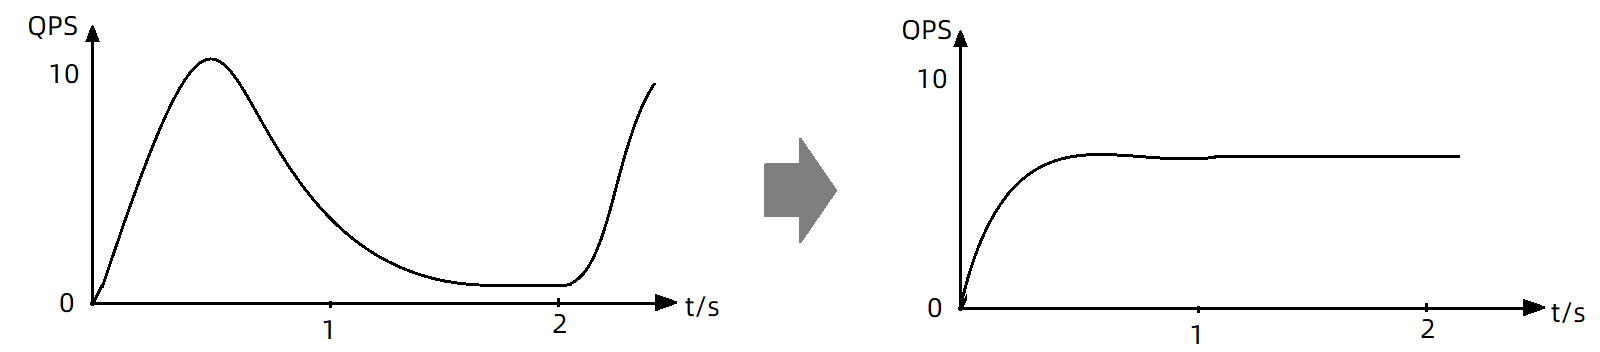

| 选择 | 结果 |
| --- | --- |
| 允许等待 | 吸收部分突发，但增加响应时间与在途资源 |
| 达到等待上限后拒绝 | 限制积压，保护下游 |
| 无限等待或无限队列 | 延迟与内存/线程占用可能持续增长 |

概念上的有界队列是一种实现；也可以预分配执行时间，用虚拟排队实现同样的节奏。算法的“桶”不必对应某个实际 Queue 对象。

适合下游固定处理速率、调用方能接受等待的场景。交互接口应把等待上限纳入总超时；后台批处理可以更宽松，但仍需要有界积压与恢复策略。


## 35. Sentinel 排队等待：预留执行时间，不是新建异步工作队列

配套 `RateLimiterController` 根据上次预留的通过时间计算本次预计等待，超过上限就拒绝，否则由调用线程等待。（课件第 59 页；配套 Sentinel 讲义第 2.9.3 章）

```text
costTime ≈ 1000 × acquireCount / QPS阈值
读取 latestPassedTime（已预留到的通过时间）
    → 计算本次预期通过时间与等待时长
    → 等待超过 maxQueueingTimeMs：拒绝
    → 在允许范围：原子预留时间槽，必要时 Thread.sleep()
    → 放行
```

课程例子：QPS=5、每请求占 1 次、最大等待 2000ms。假定系统空闲，突发同时到达，忽略线程调度与计算误差：

| 请求序号 N | 预计等待 (N−1)×200ms | 结果 |
| --- | --- | --- |
| 1 | 0ms | 立即 |
| 2 | 200ms | 等待 |
| 6 | 1000ms | 等待 |
| 11 | 2000ms | 在边界上可接受 |
| 12 | 2200ms | 超限拒绝 |

因此不能只用 `5×2=10` 就宣称实际队列容量固定为 10；首个立即位置、已有预约、请求成本和并发计算都会影响可接纳数量。

补充/校正：讲义实现没有“把所有请求装进显式队列，再由独立 worker 异步执行”。它通过 `latestPassedTime` 预留时间，允许时 `Thread.sleep`；等待仍占用调用线程。吞吐速率控制与处理完成速率也不同，下游执行很慢时仍需并发限制。


## 36. 令牌桶：速率与突发容量为什么是两个参数

漏桶趋向平滑输出，令牌桶则允许先积累额度，让短时突发通过。（课件第 61 页）

以每秒 r 个令牌补充，最多保存 B 个；请求消耗 C 个令牌。有足够令牌则通过，不足时等待或拒绝，具体行为由实现决定。

```text
tokens = min(B, oldTokens + r × elapsedSeconds)
若 tokens >= C：tokens -= C，放行
否则：按实现等待或拒绝
```

| 参数 | 含义 | 示例 |
| --- | --- | --- |
| r | 持续补充速率 | 10 个令牌/秒 |
| B | 桶容量，限制可积累突发额度 | 20 个令牌 |
| C | 单次请求成本 | 1 个令牌/次 |

桶满时可以立即处理 20 个请求；之后需要等新令牌产生。持续平均处理能力受 r/C 限制，短时可突发 B/C。理想连续补充模型中，长度 T 的区间最多可用额度约为 `B+rT`，不能说设置 r=10 就意味着任意 1 秒绝不超过 10 次。

实践中把额度更新与扣减做成原子操作，明确空桶行为。昂贵请求可设置更高成本；容量太大，会把过大的瞬时压力直接转给下游。具体离散时钟与取整可能使边界与理想公式有差异。


## 37. Sentinel 与 Gateway 限流：比较算法，也比较部署范围

“用哪个框架”不能唯一确定算法和额度范围，要看具体规则、实现及接入位置。（课件第 62 页；官方 Gateway 3.1.8 核对）

| 维度 | Sentinel 课程/讲义主线 | Gateway RedisRateLimiter |
| --- | --- | --- |
| 常见位置 | 服务内部接口、方法、远程依赖 | 网关入口路由 |
| 默认快速失败流控 | 依据滑动时间桶统计判断 | Redis 令牌桶 |
| 排队等待 | RateLimiterController，漏桶式预留时间 | 此 Redis 限流器通常额度不足直接拒绝 |
| 热点参数流控 | 讲义以参数维度令牌桶解释 | 可按 KeyResolver 给出的身份维度分桶 |
| 熔断 | 统计慢调用/异常并切换断路器状态 | 需额外配置 CircuitBreaker 等能力 |
| 多实例额度 | 普通本地规则通常每进程单独计数 | 多网关共享 Redis、相同路由与身份键时可集中计数 |

WarmUp 是动态阈值/预热策略，仍会使用流量统计；不能简单说 Sentinel 所有模式只有一个算法。Gateway 也支持不同 RateLimiter，实现为 RedisRateLimiter 时才对应这里的令牌桶。

补充配置示例：按已认证的 Principal 名称分桶，避免直接相信用户可随意修改的查询参数。

```java
package com.example.gateway;

import org.springframework.cloud.gateway.filter.ratelimit.KeyResolver;
import org.springframework.context.annotation.Bean;
import org.springframework.context.annotation.Configuration;

@Configuration
public class RateLimitKeyConfiguration {
    @Bean
    public KeyResolver userKeyResolver() {
        return exchange -> exchange.getPrincipal()
                .map(principal -> principal.getName());
    }
}
```

以下 YAML 使用展开式参数。还需匹配的 Gateway、LoadBalancer/发现依赖及 `spring-boot-starter-data-redis-reactive`，并完成 Redis 连接与鉴权配置：

```yaml
spring:
  cloud:
    gateway:
      routes:
        - id: item-query
          uri: lb://item-service
          predicates:
            - Path=/items/**
          filters:
            - name: RequestRateLimiter
              args:
                key-resolver: "#{@userKeyResolver}"
                redis-rate-limiter.replenishRate: 10
                redis-rate-limiter.burstCapacity: 20
                redis-rate-limiter.requestedTokens: 1
```

`replenishRate` 为补充速率，`burstCapacity` 为容量，`requestedTokens` 为请求成本；不要把容量当成任意滚动 1 秒的绝对次数上限。该版本未解析到 key 默认拒绝，拒绝响应默认为 **HTTP 429**；未认证请求需明确身份与规则。

集中限流需要原子额度更新，也需决定 Redis 不可用时如何降级。网关防入口冲击，服务内部保护依赖调用；网关限流不能覆盖所有绕过网关的调用。


## 38. 复现清单与面试回答

背出类名不等于能判断实现是否正确。复现时先固定组件版本和输入条件，再观察状态、金额、时间与错误信号。（补充验证方法）

| 主题 | 验证场景 | 应核对的结果 |
| --- | --- | --- |
| AT | 两个 AT 事务竞争同一行，首个全局回滚 | 后者受全局锁限制；重试/超时能释放本地锁，前者可恢复 |
| AT 脏数据 | AT 一阶段后，用非代理入口修改数据 | 回滚发现 after-image 不匹配，不盲目覆盖；留下恢复依据 |
| TCC | Try→Confirm、Try→Cancel，各阶段重复 | 金额守恒，无重复冻结/消费/释放 |
| TCC 乱序 | Cancel→Try、Try 与 Cancel 并发 | 有取消标记和并发约束，不留下悬挂预留 |
| 通知 | 提交后发送前、消费提交后 ACK 前退出 | Outbox 能恢复发送；重复消息不重复更新；可查询与对账 |
| 环境隔离 | 同服务名、不同 Namespace/Group | 调用方只发现目标空间/组内实例 |
| 服务健康 | 正常注销、强制退出、心跳中断 | 记录状态变化与缓存刷新时间，不假设瞬时摘除 |
| 负载均衡 | 固定候选列表，记录目标地址与机房 | 验证实际 Bean、轮询/随机/权重及作用服务范围 |
| 窗口限流 | 在 999ms 和 1001ms 各提交 3 次 | 固定窗口可出现边界突发；分桶统计精度有边界 |
| 排队等待 | 空闲时突发，QPS=5、等待上限=2000ms | 观察约 200ms 的准入间隔、拒绝位置及线程等待 |
| 令牌桶 | 耗尽 B=20，再等待补充 | 初始突发与持续补充不同；拒绝/恢复符合实际时钟 |
| 多实例限额 | 扩为两台服务或网关 | 区分每进程规则与共享额度，核对实际聚合维度 |

本篇完成资料与示例的静态核对，**上表服务实验未执行**。工程复现时补齐实际日志、指标和故障恢复证据，不能把表中预期写成已测结果。

官方补充来源：

- [Seata AT 模式](https://seata.apache.org/docs/user/mode/at/)与[AT 机制说明](https://seata.apache.org/docs/dev/mode/at-mode)：核对全局锁、数据库锁、读取隔离与撤销日志。
- [Spring Cloud Commons 3.1.8 · LoadBalancer](https://docs.spring.io/spring-cloud-commons/docs/3.1.8/reference/html/#spring-cloud-loadbalancer)：核对默认算法、Supplier 与自定义配置范围。
- [Spring Cloud Gateway 3.1.8 · RequestRateLimiter](https://docs.spring.io/spring-cloud-gateway/docs/3.1.8/reference/html/#the-requestratelimiter-gatewayfilter-factory)：核对 Redis 令牌桶、参数、KeyResolver 和拒绝行为。

**面试提示**：按“问题→机制→故障边界→验证”回答。CAP 说明分区期间 C/A 取舍；AT 说明一阶段本地提交、全局锁和 after-image 校验；TCC 说明预留、幂等、空回滚与防悬挂；最大努力通知说明重试加查询/对账；Nacos 说明身份隔离、分级模型、健康与缓存，并限定 1.4.2 源码背景；Feign 说明发现列表→选实例→重构 URI；服务保护先区分并发准入与 QPS，再比较分桶滑动、漏桶等待和令牌桶突发。最后交代普通 Sentinel 本地规则与网关 Redis 集中额度的范围差异。
